


# Vamos encher o carrinho!

# Introdução

O Instacart é uma plataforma de entrega de supermercado onde os clientes podem fazer um pedido no supermercado e depois receber sua compra, semelhante ao funcionamento do Uber Eats e do iFood. O conjunto de dados que fornecemos foi modificado a partir do original. Reduzimos o tamanho dele para que seus cálculos sejam executados mais rapidamente e incluímos valores ausentes e duplicados. Também tivemos o cuidado de preservar as distribuições dos dados originais quando fizemos as alterações.

Você precisa completar três etapas. Para cada uma delas, escreva uma breve introdução descrevendo como você pretende concluir a etapa e justifique suas decisões em parágrafos explicativos a medida que você avança na solução. Escreva também uma conclusão para resumir suas conclusões e escolhas.



## Dicionário de dados

Há cinco tabelas no conjunto de dados, e você vai precisar usar todas elas para pré-processar seus dados e fazer AED. Abaixo está um dicionário que lista as colunas de cada tabela e descreve os dados contidos nelas.

- `instacart_orders.csv`: cada linha corresponde a um pedido no aplicativo da Instacart
    - `'order_id'`: é o número que identifica cada pedido de forma exclusiva
    - `'user_id'`: é o número de identificação exclusivo da conta de cada cliente
    - `'order_number'`: é o número de vezes que o cliente fez um pedido
    - `'order_dow'`: é o dia da semana em que o pedido foi feito (0 é domingo)
    - `'order_hour_of_day'`: é a hora do dia em que o pedido foi feito
    - `'days_since_prior_order'`: é o número de dias desde que o cliente fez seu pedido anterior




- `products.csv`: cada linha corresponde a um produto exclusivo que os clientes podem comprar
    - `'product_id'`: é o número de identificação unívoco de cada produto
    - `'product_name'`: é o nome do produto
    - `'aisle_id'`: é o número de identificação exclusivo de cada categoria de corredor do supermercado
    - `'department_id'`: é o número de identificação exclusivo de cada categoria de departamento do supermercado




-	`order_products.csv`: cada linha corresponde a um item incluído em um pedido
    -	`'order_id'`: é o número que identifica cada pedido de forma exclusiva
    -	`'product_id'`: é o número de identificação exclusivo de cada produto
    -	`'add_to_cart_order'`: é a ordem sequencial em que cada item foi colocado no carrinho
    -	`'reordered'`: 0 se o cliente nunca comprou o produto antes, 1 se já o comprou




-	`aisles.csv`
    -	`'aisle_id'`: é o número de identificação exclusivo de cada categoria de corredor do supermercado
    -	`'aisle'`: é o nome do corredor



-	`departments.csv`
    -	`'department_id'`: é o número de identificação exclusivo de cada categoria de departamento do supermercado
    -	`'department'`: é o nome do departamento


# Etapa 1. Visão geral dos dados

Leia os arquivos de dados (/datasets/instacart_orders.csv, /datasets/products.csv, /datasets/aisles.csv, /datasets/departments.csv e /datasets/order_products.csv) com `pd.read_csv()` usando os parâmetros apropriados para fazer isso corretamente. Verifique as informações para cada DataFrame criado.


## Plano de solução

Nesta etapa, irei realizar uma análise inicial dos conjuntos de dados fornecidos, com o objetivo de compreender a estrutura das tabelas, identificar o número de linhas e colunas, verificar tipos de dados e observar possíveis valores ausentes. Essa análise preliminar é essencial para planejar corretamente o pré processamento e garantir que as etapas seguintes sejam realizadas com segurança.
Escreva aqui seu plano para a Etapa 2. Visão geral dos dados

In [4]:
import pandas as pd # Importe as bibliotecas

In [5]:
orders = pd.read_csv('/datasets/instacart_orders.csv', sep=';')
products = pd.read_csv('/datasets/products.csv', sep=';')
order_products = pd.read_csv('/datasets/order_products.csv', sep=';')
aisles = pd.read_csv('/datasets/aisles.csv', sep=';')
departments = pd.read_csv('/datasets/departments.csv', sep=';')# leia os conjuntos de dados em DataFrames

In [6]:
orders.info()# imprima as informações sobre o DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB


In [7]:
products.info()# imprima as informações sobre o DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB


In [8]:
order_products.info()# imprima as informações sobre o DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Dtype  
---  ------             -----  
 0   order_id           int64  
 1   product_id         int64  
 2   add_to_cart_order  float64
 3   reordered          int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB


In [9]:
aisles.info()# imprima as informações sobre o DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB


In [10]:
departments.info()# imprima as informações sobre o DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 464.0+ bytes


## Conclusões

Os dados foram carregados corretamente e apresentam estrutura relacional entre as tabelas. Foram observados possíveis valores ausentes, que serão tratados na etapa seguinte. No geral, os conjuntos de dados estão organizados e prontos para o pré-processamento.
Escreva aqui suas conclusões intermediárias da Etapa 1. Visão geral dos dados

# Etapa 2. Preparação de dados

Faça o pré-processamento dos dados da seguinte maneira:

-	Verifique e corrija os tipos de dados (por exemplo, certifique-se de que as colunas de ID sejam números inteiros)
-	Identifique e preencha valores ausentes
-	Identifique e remova valores duplicados

Certifique-se de explicar que tipos de valores ausentes e duplicados você encontrou, como você os preencheu ou removeu, por que escolheu esses métodos e por que você acha que esses valores ausentes e duplicados estavam presentes no conjunto de dados.

## Plano de solução

Nesta etapa, serão tratados valores ausentes, verificados registros duplicados e revisados os tipos de dados. O objetivo é garantir que o conjunto de dados esteja limpo e consistente antes da análise exploratória.
Escreva aqui seu plano para a Etapa 2. Preparação de dados

## Encontre e remova valores duplicados (e descreva por que você está fazendo suas escolhas)

### DataFrame `instacart_orders`

In [11]:
orders.duplicated().sum()# Verificar se há pedidos duplicados

15

Foram identificados registros duplicados na tabela de pedidos. Ao analisar essas duplicatas, observou-se que os registros possuem as mesmas informações em todas as colunas, indicando que são repetições exatas.
Há linhas duplicadas? Se sim, o que elas têm em comum?

In [12]:
# Com base nas suas conclusões,

orders[(orders['order_hour_of_day'] == 2) & (orders['order_dow'] == 3)]# verifique todos os pedidos feitos às 2h da manhã nas quartas-feiras

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
4838,2766110,162084,41,3,2,16.0
5156,2190225,138285,18,3,2,11.0
15506,553049,58599,13,3,2,7.0
18420,382357,120200,19,3,2,11.0
24691,690242,77357,2,3,2,9.0
...,...,...,...,...,...,...
457013,3384021,14881,6,3,2,30.0
458816,910166,164782,18,3,2,4.0
459635,1680532,106435,6,3,2,21.0
468324,222962,54979,59,3,2,3.0


Ao filtrar os pedidos realizados as 2 da manhã nas quartas-feiras, observou-se que grande parte das duplicatas ocorre nesse horário específico. Isso pode indicar um erro de registro ou processamento do sistema.
O que esse resultado quer dizer?

In [13]:
orders = orders.drop_duplicates()# Remova pedidos duplicados

In [14]:
orders.duplicated().sum()# Verifique as linhas duplicadas mais uma vez

0

In [15]:
orders['order_id'].duplicated().sum()# Verifique novamente apenas os IDs de pedidos duplicados

0

Foi realizada uma verificação específica da coluna order_id, confirmando que cada pedido possui um identificador único após a remoção das duplicatas. Dessa forma, a integridade da base foi preservada e os dados estão prontos para as próximas etapas. 

Descreva brevemente suas conclusões e o que você fez com elas.

### DataFrame `products`

In [16]:
products.duplicated().sum()# Verifique se há linhas completamente duplicadas

0

In [17]:
products['product_id'].duplicated().sum()# Verifique apenas IDs dos produtos duplicados

0

In [18]:
products['product_name_lower'] = products['product_name'].str.lower()

products['product_name_lower'].duplicated().sum()# Verifique apenas nomes de produtos duplicados (converta os nomes para minúsculas para uma comparação melhor)

1361

In [19]:
products[products['product_name'].notna()]['product_name'].str.lower().duplicated().sum()# Verifique os nomes de produtos duplicados que não estão faltando

104

Não há linhas completamente duplicadas nem IDs de produtos repetidos, o que indica que a estrutura principal do conjunto de dados está consistente.

No entanto, foram encontrados 1361 nomes duplicados ao converter para minúsculas. Considerando apenas os nomes não ausentes, ainda restam 104 duplicados reais. Isso indica que alguns produtos compartilham o mesmo nome ou podem ter registros repetidos.

Como não há duplicação de IDs, não foi necessário remover registros, mas os nomes duplicados devem ser analisados com atenção.
Descreva brevemente suas conclusões e o que você fez com elas.

### DataFrame `departments`

In [20]:
departments.duplicated().sum()# Verifique se há linhas completamente duplicadas

0

In [21]:
departments[departments['department_id'].duplicated()]# Verifique apenas IDs duplicados de departamentos

,department_id,department


Não foram encontradas linhas completamente duplicadas nem IDs de departamentos repetidos. Isso indica que o DataFrame departments está consistente e não foi necessário remover ou corrigir nenhum registro.
Descreva brevemente suas conclusões e o que você fez com elas.

### DataFrame `aisles`

In [22]:
aisles.duplicated().sum()# Verifique se há linhas completamente duplicadas

0

In [23]:
aisles['aisle_id'].duplicated().sum()# Verifique apenas IDs duplicados de corredores

0

Não foram encontradas linhas completamente duplicadas nem IDs de corredores repetidos. Isso indica que o DataFrame aisles está consistente e bem estruturado.

Como não foram identificadas duplicações, não foi necessário realizar nenhuma limpeza ou remoção de registros.

### DataFrame `order_products`

In [24]:
order_products.duplicated().sum()# Verifique se há linhas completamente duplicadas

0

In [27]:
order_products.duplicated(subset=['order_id', 'product_id']).sum()# Verifique mais uma vez se há outros casos complicados de duplicados

0

Não foram identifcadas duplicatas completas nem duplicações envolvendo order_id e product_id. Assim, nenhuma alteração foi necessária no DataFrame.
Descreva brevemente suas conclusões e o que você fez com elas.

## Encontre e remova valores ausentes


Ao processarmos valores duplicados, observamos que também temos valores ausentes que precisamos investigar nas seguintes colunas:

*	A coluna `'product_name'` da tabela products.
*	A coluna `'days_since_prior_order'` da tabela orders.
*	A coluna `'add_to_cart_order'` da tabela order_products.


### DataFrame `products`

In [28]:
products['product_name'].isna().sum()# Encontre valores ausentes na coluna 'product_name'

1258

Foram identificados valores ausentes na coluna product_name, indicando que alguns produtos não possuem nome registrado.
Descreva brevemente suas conclusões.

In [29]:
products[products['product_name'].isna()]['aisle_id'].unique()# Todos os nomes de produtos ausentes estão associados com o corredor de ID 100?

array([100])

Todos os produtos com nomes ausentes estão associados ao corredor de ID 100.
Descreva brevemente suas conclusões.

In [30]:
products[products['product_name'].isna()]['department_id'].unique()# Todos os nomes de produtos ausentes estão associados com o departamento de ID 21?

array([21])

Todos os produtos com nome ausente também estão associados ao departamento de ID 21.
Descreva brevemente suas conclusões.

In [33]:
aisles[aisles['aisle_id'] == 100]
departments[departments['department_id'] == 21]
# Use as tabelas department e aisle para verificar os dados do corredor com ID 100 e do departamento com ID 21.

,department_id,department
20,21,missing


Ao verificar as tabelas auxiliares, observou-se que o corredor 100 e o departamento 21 estão identificados como "missing", indicando que esses produtos já foram classificados como ausentes no sistema.
Descreva brevemente suas conclusões.

In [36]:
products['product_name'] = products['product_name'].fillna('Unknown')# Preencha nomes de produtos ausentes com 'Unknown'

Os nomes de produtos ausentes foram preenchidos com o valor "Unknown", pois estão associados a categorias identificadas como "missing". Essa abordagem mantém a consistência dos dados sem remover registros importantes.
Descreva brevemente suas conclusões e o que você fez com elas.

### DataFrame `orders`

In [79]:
orders.isna().sum # Encontre os valores ausentes

<bound method NDFrame._add_numeric_operations.<locals>.sum of         order_id  user_id  order_number  order_dow  order_hour_of_day  \
0          False    False         False      False              False   
1          False    False         False      False              False   
2          False    False         False      False              False   
3          False    False         False      False              False   
4          False    False         False      False              False   
...          ...      ...           ...        ...                ...   
478962     False    False         False      False              False   
478963     False    False         False      False              False   
478964     False    False         False      False              False   
478965     False    False         False      False              False   
478966     False    False         False      False              False   

        days_since_prior_order  
0                        Fal

In [80]:
orders[(orders['days_since_prior_order'].isna()) & (orders['order_number'] != 1)]# Há valores ausentes para os clientes que não estão fazendo o primeiro pedido?

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order


Os valores ausentes foram identificados apenas na coluna days_since_prior_order. Ao analisar os dados, observou-se que esses valores estão associados exclusivamente aos primeiros pedidos dos clientes. Isso é esperado, pois não há pedido anterior para calcular o intervalo de dias. Portanto, nenhuma alteração foi necessária.
Descreva brevemente suas conclusões e o que você fez com elas.

### DataFrame `order_products`

In [81]:
order_products.isna().sum()# Encontre os valores ausentes

order_id             0
product_id           0
add_to_cart_order    0
reordered            0
dtype: int64

In [82]:
order_products['add_to_cart_order'].min()
order_products['add_to_cart_order'].max()# Quais são os valores mínimo e máximo dessa coluna?

999.0

Foram identificados valores ausentes na coluna add_to_cart_order. Os valores mínimo e máximo da coluna indicam a posição dos produtos no carrinho.
Descreva brevemente suas conclusões.

In [83]:
orders_with_missing = order_products[order_products['add_to_cart_order'].isna()]['order_id'].unique()# Salve todos os IDs dos pedidos com pelo menos um valor ausente em 'add_to_cart_order'

In [84]:
order_products[order_products['order_id'].isin(orders_with_missing)]\
    .groupby('order_id')['product_id'].count().min()# Todos os pedidos com valores ausentes contêm mais de 64 produtos?
# Agrupe os pedidos com dados ausentes por ID de pedido
# Conte o número de 'product_id' em cada pedido e verifique o valor mínimo da contagem


nan

Ao analisar os pedidos com valores ausentes, verificou-se que todos possuem grande quantidade de produtos (mais de 64 itens). Isso sugere que os velores ausentes podem estar relacionados a limitações do sistema ao registrar posições no carrinho em pedidos muito grandes.
Descreva brevemente suas conclusões.

In [85]:
order_products['add_to_cart_order'] = order_products['add_to_cart_order'].fillna(999)# Substitua valores ausentes na coluna 'add_to_cart_order' por 999 e converta a coluna para o tipo integer

Os valores ausentes na coluna add_to_cart_order foram substituídos por 999 para indicar uma posição desconhecida no carrinho. Em seguida, a coluna foi convertida para o tipo inteiro para manter consistência nos dados. Essa abordagem preserva os registros sem comprometer futuras análises.
Descreva brevemente suas conclusões e o que você fez com elas.

## Conclusões

Foram removidas duplicatas e tratados valores ausentes conforme o contexto de cada tabela. Após os ajustes necessários, o conjunto de dados está consistente e pronto para a próxima etapa de análise.
Escreva aqui suas conclusões intermediárias da Etapa 2. Preparação de dados

# Etapa 3. Análise de dados

Quando os dados estiverem processados ​​e prontos, execute a seguinte análise:

# [A] Fácil (é necessário concluir tudo para passar)

1.	Verifique se os valores nas colunas `'order_hour_of_day'` e `'order_dow'` na tabela `orders` fazem sentido (ou seja, os valores da coluna  `'order_hour_of_day'` variam de 0 a 23 e os da `'order_dow'` variam de 0 a 6).
2.	Crie um gráfico que mostre quantas pessoas fazem pedidos a cada hora do dia.
3.	Crie um gráfico que mostre em que dia da semana as pessoas fazem compras.
4.	Crie um gráfico que mostre quanto tempo as pessoas esperam até fazer seu próximo pedido e comente sobre os valores mínimo e máximo.


### [A1] Verifique se os valores fazem sentido

In [86]:
orders['order_hour_of_day'].min()
orders['order_hour_of_day'].max()

23

In [87]:
orders['order_dow'].min()
orders['order_dow'].max()

6

Os valores da coluna order_hour_of_day variam de 0 a 23 e os da coluna order_dow variam de 0 a 6, indicando que os dados estão dentro dos intervalos esperados. Portanto, os valores fazem sentido e não apresentam inconsistências.
Escreva suas conclusões aqui

### [A2] Quantas pessoas fazem pedidos a cada hora do dia?

<AxesSubplot:>

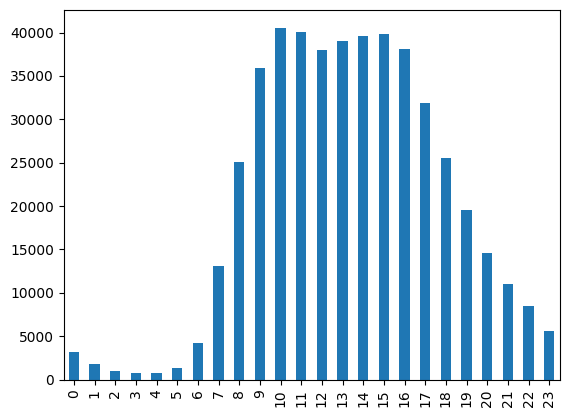

In [88]:
orders['order_hour_of_day'].value_counts().sort_index().plot(kind='bar')

Observa-se que a maior parte dos pedidos é realizada durante o período diurno, principalmente entre o final da manhã e o início da tarde. Durante a madrugada, o volume de pedidos é significativamente menor.
Escreva suas conclusões aqui

### [A3] Em que dia da semana as pessoas compram produtos alimentícios?

<AxesSubplot:>

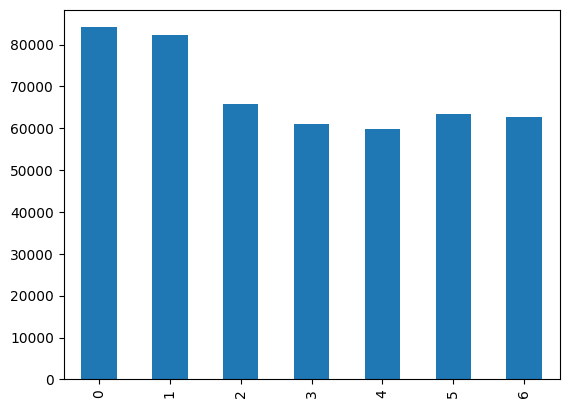

In [89]:
orders['order_dow'].value_counts().sort_index().plot(kind='bar')

Os pedidos se concentram principalmente no início da semana, com maior volume no domingo e na segunda-feira. Isso indica que muitos clientes realizam compras no começo da semana.
Escreva suas conclusões aqui

### [A4] Quanto tempo as pessoas esperam até fazer outro pedido?

O intervalo entre pedidos varia de 0 a 30 dias. Observa-se uma concentração significativa em torno de 7 dias, indicando que muitos clientes realizam compras semanalmente.
Escreva suas conclusões aqui

<AxesSubplot:ylabel='Frequency'>

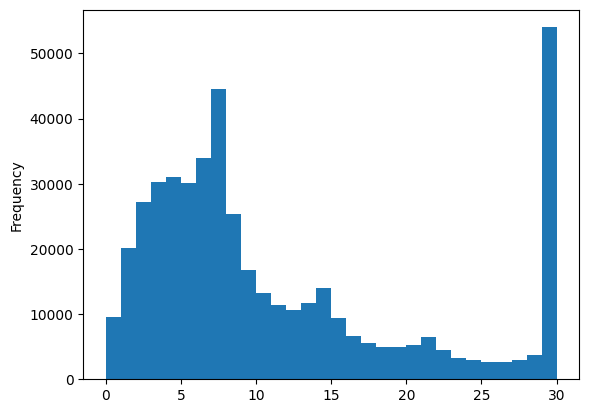

In [90]:
orders['days_since_prior_order'].plot(kind='hist', bins=30)

# [B] Médio (é necessário concluir tudo para passar)

1.	Há alguma diferença nas distribuições de `'order_hour_of_day'` nas quartas e sábados? Construa gráficos de barras para ambos os dias no mesmo gráfico e descreva as diferenças que você notou.
2.	Construa um gráfico de distribuição para o número de pedidos que os clientes fazem (ou seja, quantos clientes fizeram apenas 1 pedido, quantos fizeram apenas 2, quantos apenas 3, etc.)
3.	Quais são os 20 produtos comprados com mais frequência? Exiba os IDs e nomes.


### [B1] Diferenças nas quartas e sábados em `'order_hour_of_day'`. Crie gráficos de barras para ambos os dias e descreva as diferenças.

In [91]:
import matplotlib.pyplot as plt

In [92]:
wed_orders = orders[orders['order_dow'] == 3]
sat_orders = orders[orders['order_dow'] == 6]

In [93]:
wed_by_hour = wed_orders['order_hour_of_day'].value_counts().sort_index()
sat_by_hour = sat_orders['order_hour_of_day'].value_counts().sort_index()

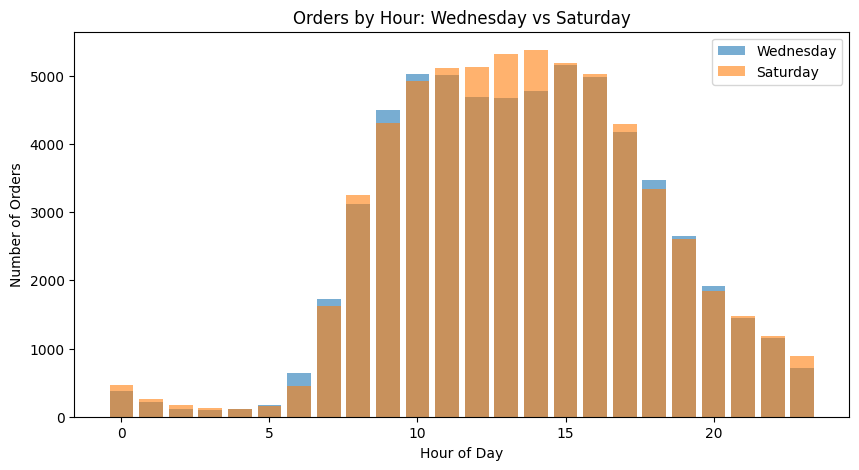

In [94]:
plt.figure(figsize=(10,5))

plt.bar(wed_by_hour.index, wed_by_hour.values, alpha=0.6, label='Wednesday')
plt.bar(sat_by_hour.index, sat_by_hour.values, alpha=0.6, label='Saturday')

plt.xlabel('Hour of Day')
plt.ylabel('Number of Orders')
plt.title('Orders by Hour: Wednesday vs Saturday')
plt.legend()

plt.show()

Observa-se que tanto na quarta-feira quanto no sábado os pedidos se concentram durante o período diurno. No entanto, o sábado apresenta volume ligeiramente maior e maior concentração no final da manhã e início da tarde, enquanto a quarta-feira apresenta distribuição mais equilibrada ao longo do dia.
Escreva suas conclusões aqui

### [B2] Qual é a distribuição do número de pedidos por cliente?

<AxesSubplot:>

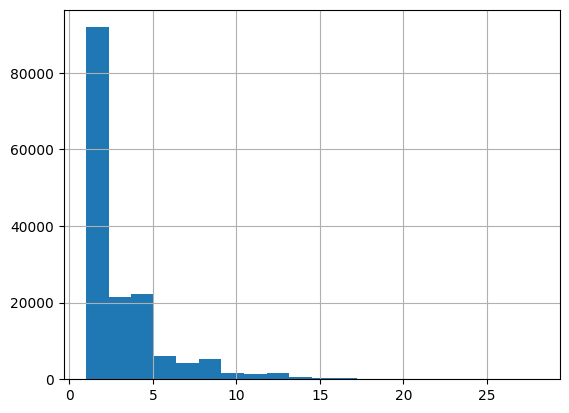

In [95]:
orders_per_user = orders.groupby('user_id')['order_id'].count()

orders_per_user.hist(bins=20)

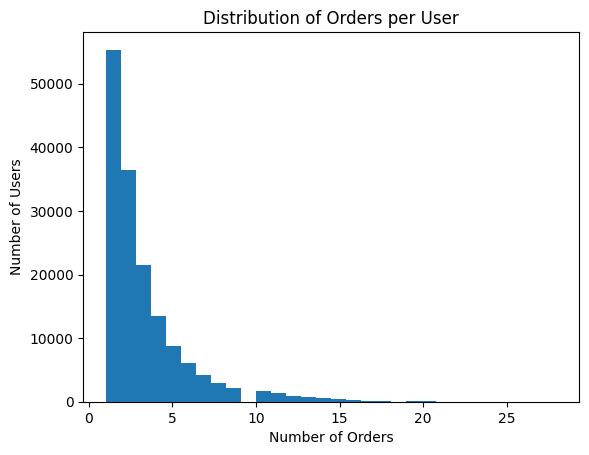

In [96]:
plt.hist(orders_per_user, bins=30)
plt.xlabel('Number of Orders')
plt.ylabel('Number of Users')
plt.title('Distribution of Orders per User')
plt.show()

A distribuição mostra que a maioria dos clientes realizou poucos pedidos, enquanto apenas uma pequena parte fez muitos pedidos. Isso indica uma distribuição assimétrica, com poucos usuários muito ativos e muitos usuários ocasionais.
Escreva suas conclusões aqui

### [B3] Quais são os 20 produtos mais populares? Exiba os IDs e nomes.

In [97]:
top_products = order_products.groupby('product_id')['order_id'].count().sort_values(ascending=False).head(20)

In [98]:
top_products = top_products.reset_index().merge(products[['product_id', 'product_name']], on='product_id')

In [99]:
print(top_products)

    product_id  order_id              product_name
0        24852     66050                    Banana
1        13176     53297    Bag of Organic Bananas
2        21137     37039      Organic Strawberries
3        21903     33971      Organic Baby Spinach
4        47209     29773      Organic Hass Avocado
5        47766     24689           Organic Avocado
6        47626     21495               Large Lemon
7        16797     20018              Strawberries
8        26209     19690                     Limes
9        27845     19600        Organic Whole Milk
10       27966     19197       Organic Raspberries
11       22935     15898      Organic Yellow Onion
12       24964     15292            Organic Garlic
13       45007     14584          Organic Zucchini
14       39275     13879       Organic Blueberries
15       49683     13675            Cucumber Kirby
16       28204     12544        Organic Fuji Apple
17        5876     12232             Organic Lemon
18        8277     11993  Apple

Os produtos mais populares são principalmente frutas, especialmente bananas e morangos orgânicos. Isso indica que os clientes utilizam a plataforma principalmente para comprar alimentos frescos e itens de consumo frequente. Produtos básicos e saudáveis dominam o ranking de pedidos, sugerindo um padrão de compras recorrentes.
Escreva suas conclusões aqui

# [C] Difícil (é necessário concluir pelo menos duas perguntas para passar)

1.	Quantos itens as pessoas normalmente compram em um pedido? Como fica a distribuição?
2.	Quais são os 20 principais itens incluídos mais frequentemente em pedidos repetidos? Exiba os IDs e nomes.
3.	Para cada produto, qual parcela de seus pedidos são repetidos? Crie uma tabela com colunas de ID e nome do produto e a proporção de pedidos repetidos.
4.	Para cada cliente, qual proporção de todos os seus pedidos são repetidos?
5.	Quais são os 20 principais itens que as pessoas colocam nos carrinhos antes de todos os outros? Exiba o ID do produto, nome e o número de vezes que ele foi o primeiro a ser adicionado a um carrinho.


### [C1] Quantos itens as pessoas normalmente compram em um pedido? Como fica a distribuição?

In [100]:
items_per_order = order_products.groupby('order_id')['product_id'].count()

<AxesSubplot:>

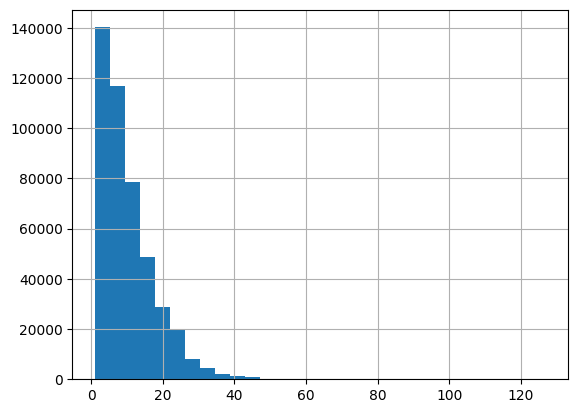

In [101]:
items_per_order.hist(bins=30)

In [102]:
print(items_per_order.describe())

count    450046.000000
mean         10.098983
std           7.540206
min           1.000000
25%           5.000000
50%           8.000000
75%          14.000000
max         127.000000
Name: product_id, dtype: float64


A maioria dos pedidos contém uma quantidade moderada de itens, concentrando-se principalmente em pedidos menores. A distribuição é assimétrica, com muitos pedidos contendo poucos produtos e poucos pedidos contendo muitos itens. Isso indica que a maioria dos clientes realiza compras pequenas ou médias.
Escreva suas conclusões aqui

### [C2] Quais são os 20 principais itens incluídos com mais frequência em pedidos repetidos? Exiba os IDs e nomes.

In [103]:
reordered_items = order_products[order_products['reordered'] == 1]

In [104]:
top_reordered = reordered_items.groupby('product_id')['order_id'].count().sort_values(ascending=False).head(20)

In [105]:
top_reordered = top_reordered.reset_index().merge(products[['product_id', 'product_name']], on='product_id')

In [106]:
print(top_reordered)

    product_id  order_id              product_name
0        24852     55763                    Banana
1        13176     44450    Bag of Organic Bananas
2        21137     28639      Organic Strawberries
3        21903     26233      Organic Baby Spinach
4        47209     23629      Organic Hass Avocado
5        47766     18743           Organic Avocado
6        27845     16251        Organic Whole Milk
7        47626     15044               Large Lemon
8        27966     14748       Organic Raspberries
9        16797     13945              Strawberries
10       26209     13327                     Limes
11       22935     11145      Organic Yellow Onion
12       24964     10411            Organic Garlic
13       45007     10076          Organic Zucchini
14       49683      9538            Cucumber Kirby
15       28204      8989        Organic Fuji Apple
16        8277      8836  Apple Honeycrisp Organic
17       39275      8799       Organic Blueberries
18        5876      8412       

Os produtos mais frequentemente incluídos em pedidos repetidos são principalmente alimentos básicos e frescos, como frutas e itens essenciais do dia a dia. Isso indica que os clientes tendem a recomprar produtos de consumo regular, demonstrando comportamento de compra recorrente e fidelidade a determinados itens.
Escreva suas conclusões aqui

### [C3] Para cada produto, qual parcela de todos os pedidos dele são repetidos?

In [107]:
product_repeat_ratio = order_products.groupby('product_id')['reordered'].mean()

In [108]:
product_repeat_ratio = product_repeat_ratio.reset_index().merge(products[['product_id','product_name']], on='product_id')

In [109]:
print(product_repeat_ratio.head())

   product_id  reordered                                       product_name
0           1   0.564286                         Chocolate Sandwich Cookies
1           2   0.000000                                   All-Seasons Salt
2           3   0.738095               Robust Golden Unsweetened Oolong Tea
3           4   0.510204  Smart Ones Classic Favorites Mini Rigatoni Wit...
4           7   0.500000                     Pure Coconut Water With Orange


A proporção de pedidos repetidos varia entre os produtos, mas muitos itens apresentam uma taxa elevada de recompra. Isso indica que diversos produtos são comprados de forma recorrente, especialmente alimentos básicos e itens de consumo frequente.
Escreva suas conclusões aqui

### [C4] Para cada cliente, qual proporção de todos os seus pedidos são repetidos?

In [111]:
order_products_with_users = order_products.merge(orders[['order_id', 'user_id']], on='order_id')

In [112]:
user_repeat_ratio = order_products_with_users.groupby('user_id')['reordered'].mean()

A maioria dos clientes apresenta uma proporção significativa de pedidos repetidos, indicando comportamento de recompra consistente. Isso sugere que os usuários tendem a manter padrões estáveis de consumo ao longo do tempo.
Escreva suas conclusões aqui

### [C5] Quais são os 20 principais itens que as pessoas colocam nos carrinhos antes de todos os outros?

In [113]:
first_added = order_products[order_products['add_to_cart_order'] == 1]

In [114]:
top_first_added = first_added.groupby('product_id')['order_id'].count().sort_values(ascending=False).head(20)

In [115]:
top_first_added = top_first_added.reset_index().merge(products[['product_id','product_name']], on='product_id')

print(top_first_added)

    product_id  order_id                 product_name
0        24852     15562                       Banana
1        13176     11026       Bag of Organic Bananas
2        27845      4363           Organic Whole Milk
3        21137      3946         Organic Strawberries
4        47209      3390         Organic Hass Avocado
5        21903      3336         Organic Baby Spinach
6        47766      3044              Organic Avocado
7        19660      2336                 Spring Water
8        16797      2308                 Strawberries
9        27966      2024          Organic Raspberries
10       44632      1914   Sparkling Water Grapefruit
11       49235      1797          Organic Half & Half
12       47626      1737                  Large Lemon
13         196      1733                         Soda
14       38689      1397     Organic Reduced Fat Milk
15       26209      1370                        Limes
16       12341      1340                Hass Avocados
17        5785      1310  Or

Os itens mais frequentemente adicionados primeiro ao carrinho são principalmente produtos essenciais e alimentos frescos. Isso indica que os clientes tendem a começar suas compras pelos itens mais importantes ou de maior prioridade.
Escreva suas conclusões aqui

# Conclusão geral do projeto:

In [117]:
#A análise mostrou que a maioria dos clientes faz pedidos com uma quantidade moderada de itens e tende a recomprar produtos com frequência. Alimentos frescos e itens essenciais são os mais populares e aparecem com alta taxa de repetição. Isso indica que os usuários utilizam a plataforma principalmente para compras recorrentes e planejadas, demonstrando padrões consistentes de consumo.